In [1]:
import pandas as pd
df_m = pd.read_csv("matches.csv")
df_m.tail(10)

,match_id,season,team_a,team_b,score_a,score_b,winner,date,stage,format
1229,S18-063,18,RRQ,ONIC,1,2,ONIC,2026-10-11,regular,BO3
1230,S18-064,18,Dewa United,Bigetron,0,2,Bigetron,2026-10-11,regular,BO3
1231,S18-065,18,NAVI,RRQ,2,1,NAVI,2026-10-16,regular,BO3
1232,S18-066,18,Geek Fam,Alter Ego,0,2,Alter Ego,2026-10-16,regular,BO3
1233,S18-067,18,ONIC,Dewa United,2,1,ONIC,2026-10-17,regular,BO3
1234,S18-068,18,Bigetron,EVOS,2,1,Bigetron,2026-10-17,regular,BO3
1235,S18-069,18,RRQ,Geek Fam,2,1,RRQ,2026-10-17,regular,BO3
1236,S18-070,18,EVOS,Alter Ego,2,1,EVOS,2026-10-18,regular,BO3
1237,S18-071,18,NAVI,Bigetron,0,2,Bigetron,2026-10-18,regular,BO3
1238,S18-072,18,ONIC,Team Liquid,0,2,Team Liquid,2026-10-18,regular,BO3


In [2]:
print("=======shape=======")
print(df_m.shape)


print("========info=======")
df_m.info()

=======shape=======
(1239, 10)
========info=======
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1239 entries, 0 to 1238
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   match_id  1239 non-null   object
 1   season    1239 non-null   int64 
 2   team_a    1239 non-null   object
 3   team_b    1239 non-null   object
 4   score_a   1239 non-null   int64 
 5   score_b   1239 non-null   int64 
 6   winner    1239 non-null   object
 7   date      1239 non-null   object
 8   stage     1239 non-null   object
 9   format    1239 non-null   object
dtypes: int64(3), object(7)
memory usage: 96.9+ KB


<Axes: >

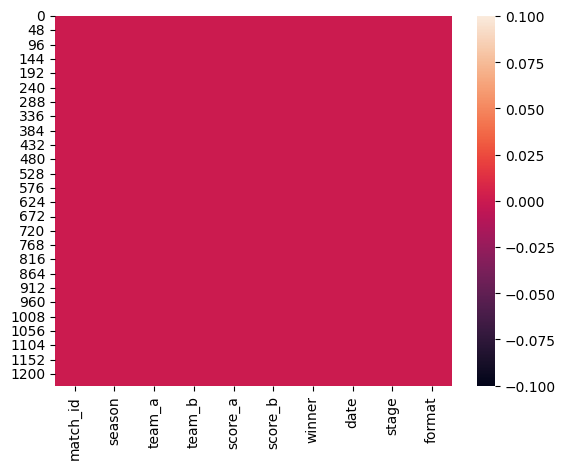

In [3]:
import seaborn as sns
sns.heatmap(df_m.isnull())

In [4]:
df_m['winner'].value_counts()

winner
ONIC               211
RRQ                179
Bigetron           161
EVOS               155
Alter Ego          132
Geek Fam            94
Aura                56
Team Liquid         50
Dewa United         43
Aerowolf            42
Rebellion           31
NAVI                24
Louvre              18
SFI Critical        11
Elite8               6
NXL                  6
Saints Indo          5
The Prime            5
Star8                4
BOOM                 2
Rev Indo             2
Pandora Esports      1
Domino Esports       1
Name: count, dtype: int64

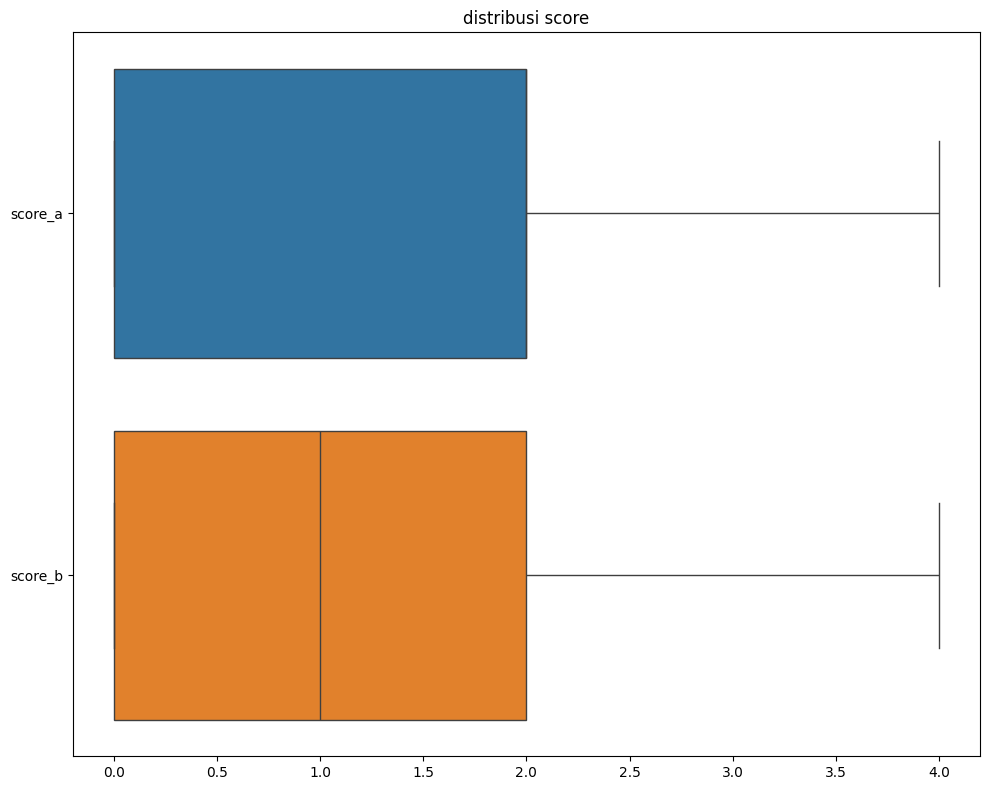

In [5]:
import matplotlib.pyplot as plt

sc_cols = df_m[['score_a', 'score_b']].columns

plt.figure(figsize=(10,8))
sns.boxplot(data=df_m[sc_cols], orient='h')
plt.title('distribusi score')
plt.tight_layout()
plt.show()


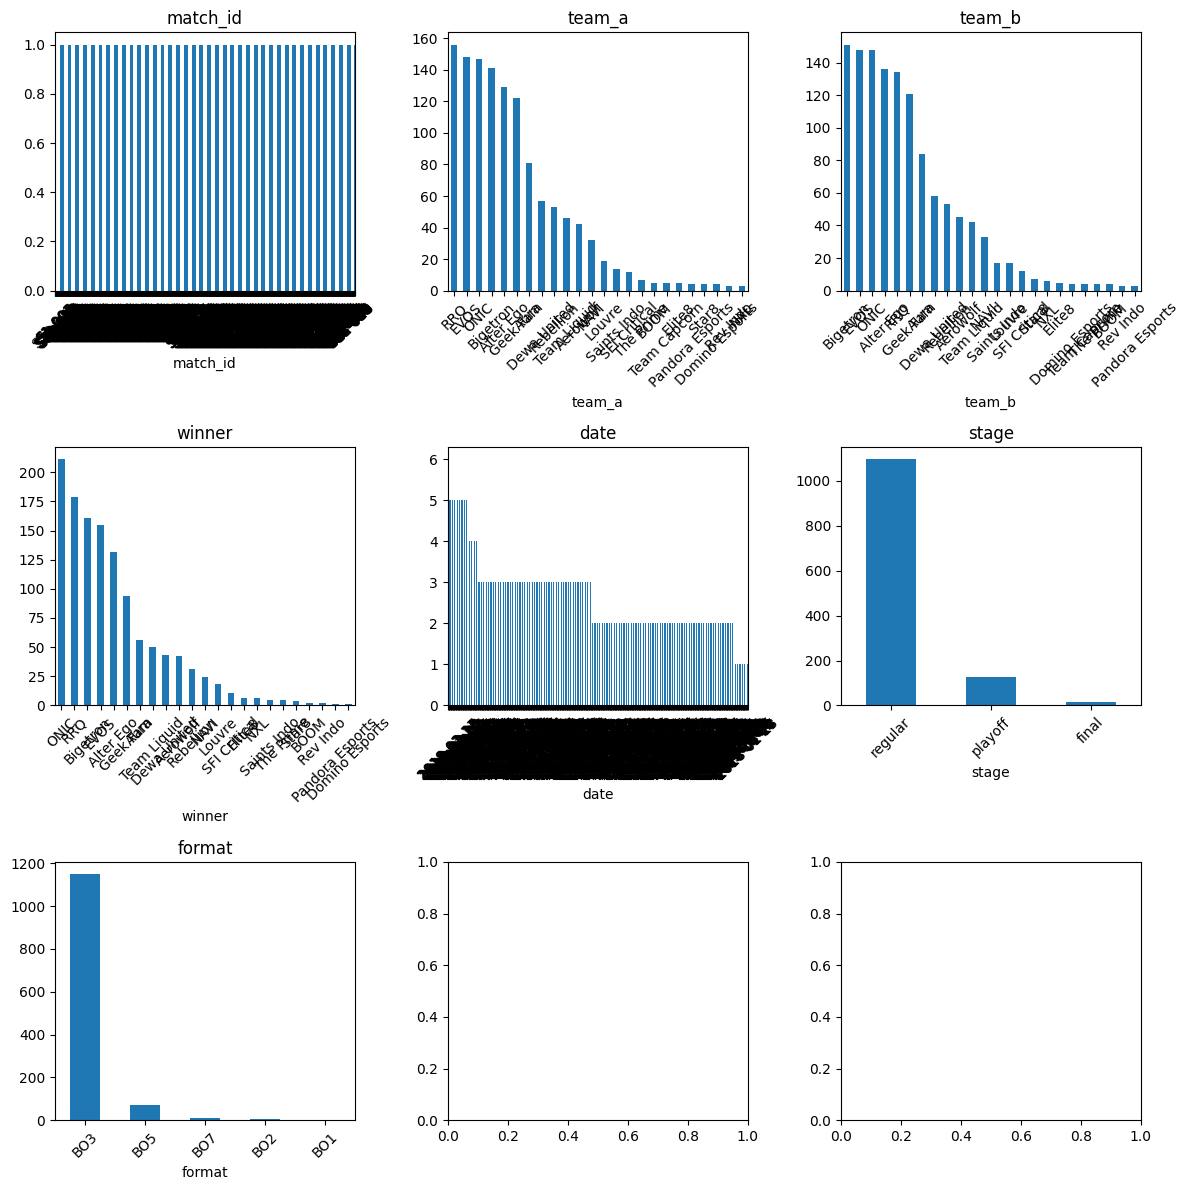

In [6]:
cat_cols = df_m.select_dtypes(include='object').columns

n = len(cat_cols)
rows = (n+2)//3

fig,axes = plt.subplots(nrows=rows, ncols=3, figsize=(12,4 * rows))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    data = df_m
    data[col].value_counts().plot(kind = 'bar', ax = axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation = 45)

plt.tight_layout()
plt.show()

In [7]:
df_m.duplicated().sum()

np.int64(0)

In [8]:
df_m['date'] = pd.to_datetime(df_m['date'])
print(df_m.dtypes)

match_id            object
season               int64
team_a              object
team_b              object
score_a              int64
score_b              int64
winner              object
date        datetime64[ns]
stage               object
format              object
dtype: object


In [19]:
df_m = df_m.sort_values(['date', 'match_id']).reset_index(drop=True)

K = 23
retain = 0.75
rating = {}
season_sekarang = df_m.loc[0, 'season']
rating_history = []


for i in range(len(df_m)):
    a = df_m.loc[i, 'team_a']
    b = df_m.loc[i, 'team_b']

    if df_m.loc[i, 'season'] != season_sekarang:
        for tim in rating:
            rating[tim] = retain * rating[tim] + (1 - retain) * 1500
        season_sekarang = df_m.loc[i, 'season']

    if a not in rating:
        rating[a] = 1500
    if b not in rating:
        rating[b] = 1500

    e_a = 1/(1 + 10 ** ((rating[b] - rating [a])/400))

    if df_m.loc[i, 'winner'] == a:
        s_a = 1
    else:
        s_a = 0

    rating[a] += K * (s_a - e_a)
    rating[b] += K * ((1 - s_a) - (1 - e_a))

    for tim, r in rating.items():
        rating_history.append({
            'match_id' : df_m.loc[i, 'match_id'],
            'date' : df_m.loc[i, 'date'],
            'team' : tim,
            'rating' : r
        })

hasil = sorted(rating.items(), key = lambda x: x[1], reverse=True)
for tim, r in hasil:
    print(tim, round(r,1))
    

ONIC 1535.5
Bigetron 1525.6
Team Liquid 1519.2
NAVI 1506.4
EVOS 1503.5
Aura 1500.5
Aerowolf 1500.0
Louvre 1500.0
NXL 1500.0
Elite8 1500.0
SFI Critical 1500.0
The Prime 1500.0
Rev Indo 1500.0
Star8 1500.0
Pandora Esports 1500.0
Domino Esports 1500.0
BOOM 1500.0
Team Capcorn 1500.0
Saints Indo 1500.0
Alter Ego 1494.5
Geek Fam 1487.8
Rebellion 1486.8
Dewa United 1473.3
RRQ 1466.7


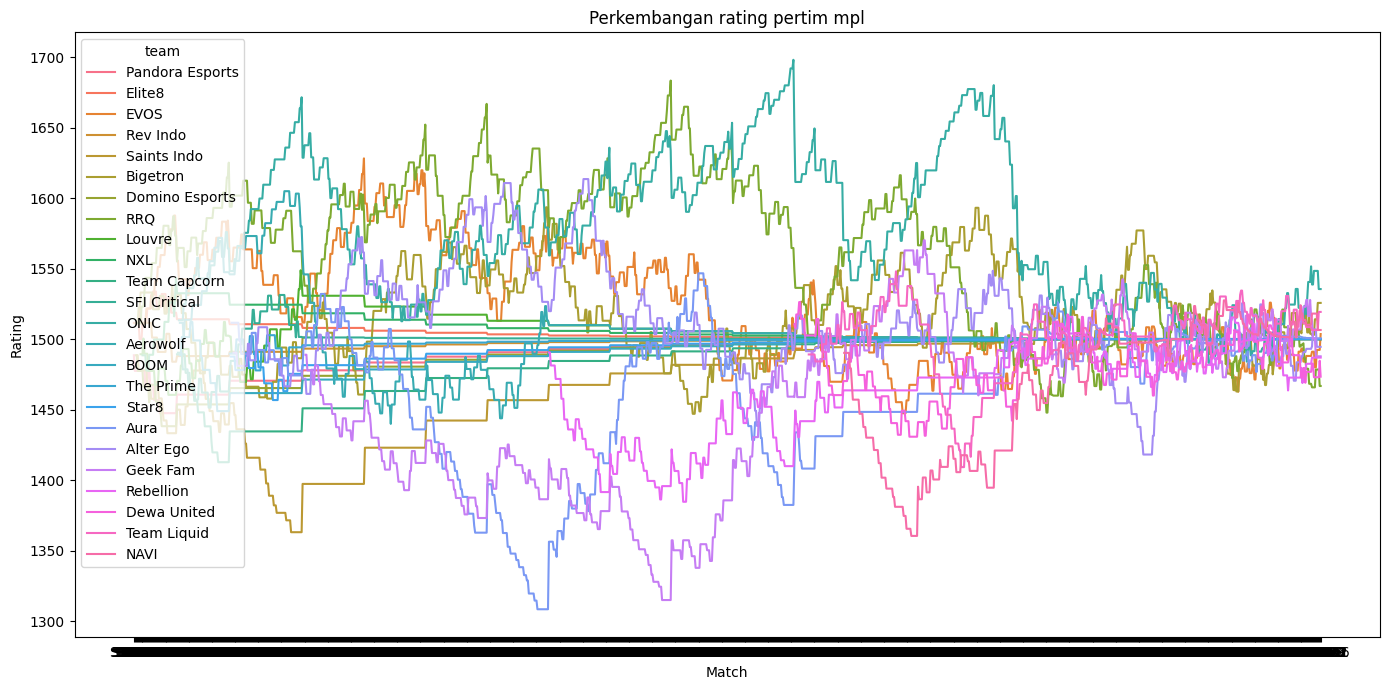

In [21]:
df_his = pd.DataFrame(rating_history)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data = df_his,
    x = 'match_id',
    y = 'rating',
    hue = 'team'
)

plt.title('Perkembangan rating pertim mpl')
plt.xlabel('Match')
plt.ylabel('Rating')
plt.tight_layout()
plt.savefig('ELo rating')
plt.show()

In [ ]:
import math as m